**STEP 1 — Load Baseline Predictions**


The objective of this notebook is not to re-run Mistral-7B.
Instead, the objective is to investigate whether alternative confidence signals derived from option likelihoods can better distinguish between correct and incorrect predictions.

Using the saved baseline outputs ensures:

- reproducibility
- computational efficiency
- direct comparability with previous experiments

Relationship to Previous Notebook

1. Notebook 01 generated:

- baseline accuracy
- confidence scores
- calibration metrics

Notebook 02 investigated:

- selective prediction using those confidence scores

This notebook extends the analysis by constructing new confidence signals from option likelihood information.


**STEP 1.1 — Import Libraries**

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

**STEP 1.2 — Load Baseline Results**

In [2]:
results_df = pd.read_csv(
    "/content/drive/MyDrive/Dissertation/baseline_option_scores.csv"
)

print(
    "Rows:",
    len(results_df)
)

Rows: 817


**STEP 1.3 — Verify Dataset Structure**

In [3]:
print(
    results_df.columns.tolist()
)

['question', 'predicted_index', 'true_index', 'confidence', 'correct', 'option_probabilities', 'option_scores', 'predicted_answer', 'true_answer']


**STEP 1.4 — Dataset Integrity Check**

In [4]:
print("=" * 60)
print("MISSING VALUES")
print("=" * 60)

print(
    results_df.isnull().sum()
)

MISSING VALUES
question                0
predicted_index         0
true_index              0
confidence              0
correct                 0
option_probabilities    0
option_scores           0
predicted_answer        0
true_answer             0
dtype: int64


**STEP 1.5 — Baseline Summary Statistics**

In [5]:
baseline_accuracy = (
    results_df["correct"]
    .astype(int)
    .mean()
)

mean_confidence = (
    results_df["confidence"]
    .mean()
)

print("=" * 60)
print("BASELINE SUMMARY")
print("=" * 60)

print(
    f"Accuracy: {baseline_accuracy:.4f}"
)

print(
    f"Mean Confidence: {mean_confidence:.4f}"
)

BASELINE SUMMARY
Accuracy: 0.5055
Mean Confidence: 0.3481


**STEP 1.6 — Confidence Distribution**

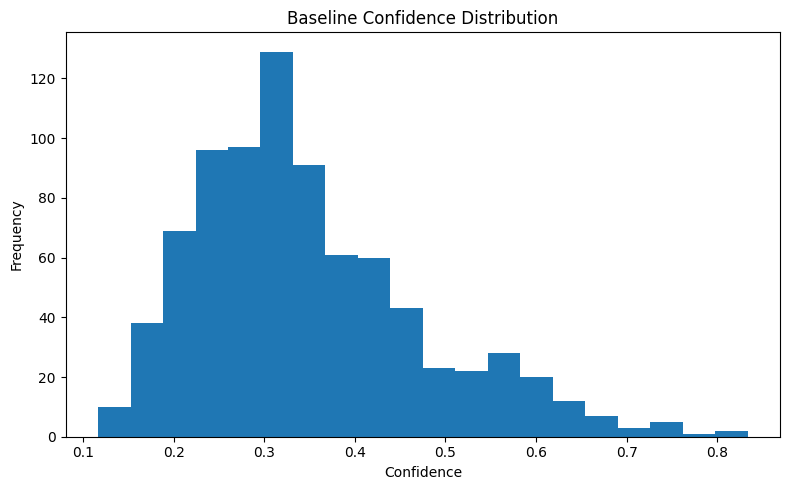

In [8]:
plt.figure(figsize=(8,5))

plt.hist(
    results_df["confidence"],
    bins=20
)

plt.xlabel("Confidence")

plt.ylabel("Frequency")

plt.title(
    "Baseline Confidence Distribution"
)


plt.tight_layout()

plt.show()

**STEP 1.7 — Confidence by Correctness**

In [9]:
summary = (

    results_df

    .groupby("correct")

    ["confidence"]

    .agg([
        "mean",
        "std",
        "min",
        "max"
    ])

)

print(summary)

             mean       std       min       max
correct                                        
False    0.307673  0.103745  0.129062  0.815361
True     0.387736  0.132860  0.116716  0.833459


**STEP 1.8 — Confidence Boxplot**

<Figure size 800x500 with 0 Axes>

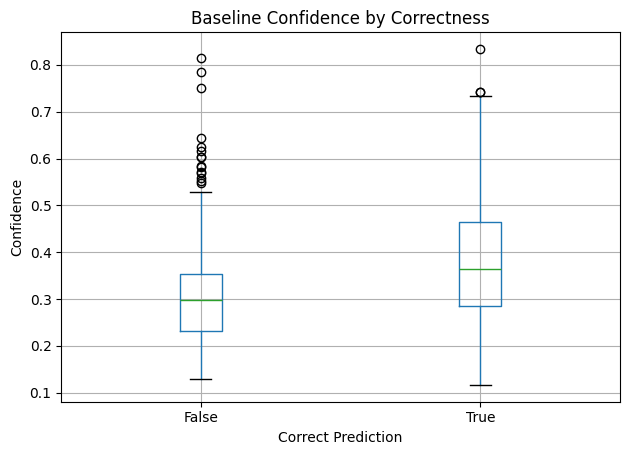

In [11]:
plt.figure(figsize=(8,5))

results_df.boxplot(
    column="confidence",
    by="correct"
)

plt.title(
    "Baseline Confidence by Correctness"
)


plt.suptitle("")

plt.xlabel(
    "Correct Prediction"
)

plt.ylabel(
    "Confidence"
)

plt.tight_layout()

plt.show()

**STEP 1.9 — Save Notebook Metadata**

In [12]:
import json

metadata = {

    "input_file":
        "baseline_predictions.csv",

    "rows":
        int(len(results_df)),

    "accuracy":
        float(baseline_accuracy)

}

with open(

    "option_likelihood_metadata.json",

    "w"

) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

The baseline results indicate that Mistral-7B achieves approximately 50% accuracy on TruthfulQA MC1 while exhibiting moderate confidence separation between correct and incorrect predictions.
Although the baseline confidence signal provides useful information, previous calibration and selective prediction analyses demonstrated that confidence remains imperfectly aligned with correctness.
The next stage of the dissertation therefore investigates whether alternative confidence signals derived from answer-option likelihoods can provide a stronger indication of prediction reliability. These signals may capture uncertainty information that is not reflected by the maximum probability alone and may therefore improve confidence estimation and calibration performance.

**STEP 2 — Construct Option Likelihood Signals**

**STEP 2.1 — Parse Option Probability Data**

In [13]:
import ast

results_df["option_probabilities"] = (
    results_df["option_probabilities"]
    .apply(ast.literal_eval)
)

print(
    results_df["option_probabilities"].iloc[0]
)

[0.2187605813534571, 0.3193407309431222, 0.29074266399498105, 0.17115602370843977]


**STEP 2.2 — Compute Entropy**

In [14]:
def compute_entropy(probs):

    probs = np.array(probs)

    probs = np.clip(
        probs,
        1e-12,
        1
    )

    entropy = -np.sum(
        probs * np.log(probs)
    )

    return entropy


results_df["entropy"] = (
    results_df["option_probabilities"]
    .apply(compute_entropy)
)

print(
    results_df["entropy"].head()
)

0    1.358274
1    1.485724
2    1.308432
3    1.333505
4    1.856746
Name: entropy, dtype: float64


**STEP 2.3 — Compute Normalised Entropy**

In [15]:
def compute_normalised_entropy(probs):

    probs = np.array(probs)

    entropy = compute_entropy(
        probs
    )

    max_entropy = np.log(
        len(probs)
    )

    return entropy / max_entropy


results_df["normalised_entropy"] = (
    results_df["option_probabilities"]
    .apply(
        compute_normalised_entropy
    )
)

print(
    results_df[
        "normalised_entropy"
    ].head()
)

0    0.979788
1    0.923132
2    0.943834
3    0.961921
4    0.954179
Name: normalised_entropy, dtype: float64


**STEP 2.4 — Compute Margin Score**

In [16]:
def compute_margin(probs):

    probs = sorted(
        probs,
        reverse=True
    )

    return (
        probs[0]
        -
        probs[1]
    )


results_df["margin_score"] = (
    results_df["option_probabilities"]
    .apply(
        compute_margin
    )
)

print(
    results_df["margin_score"].head()
)

0    0.028598
1    0.229115
2    0.228116
3    0.146043
4    0.138779
Name: margin_score, dtype: float64


**STEP 2.5 — Compute Probability Gap**

In [17]:
results_df["probability_gap"] = (
    results_df["margin_score"]
)

print(
    results_df[
        "probability_gap"
    ].head()
)

0    0.028598
1    0.229115
2    0.228116
3    0.146043
4    0.138779
Name: probability_gap, dtype: float64


In [18]:
print(
    np.allclose(
        results_df["margin_score"],
        results_df["probability_gap"]
    )
)

True


In this experiment, probability gap and margin score are mathematically equivalent because both are defined as the difference between the highest and second-highest option probabilities. Both names are retained because different uncertainty estimation literature uses different terminology.

**STEP 2.6 — Create Signal Dataset**

In [19]:
signal_df = results_df[[
    "confidence",
    "entropy",
    "normalised_entropy",
    "margin_score",
    "probability_gap",
    "correct"
]].copy()

print(
    signal_df.head()
)

   confidence   entropy  normalised_entropy  margin_score  probability_gap  \
0    0.319341  1.358274            0.979788      0.028598         0.028598   
1    0.410306  1.485724            0.923132      0.229115         0.229115   
2    0.430482  1.308432            0.943834      0.228116         0.228116   
3    0.384879  1.333505            0.961921      0.146043         0.146043   
4    0.294637  1.856746            0.954179      0.138779         0.138779   

   correct  
0    False  
1     True  
2     True  
3     True  
4     True  


**STEP 2.7 — Signal Summary Statistics**

In [20]:
summary_stats = (
    signal_df
    .describe()
)

print(
    summary_stats
)

       confidence     entropy  normalised_entropy  margin_score  \
count  817.000000  817.000000          817.000000    817.000000   
mean     0.348145    1.470718            0.945166      0.109493   
std      0.125827    0.358431            0.056431      0.115801   
min      0.116716    0.450359            0.585361      0.000286   
25%      0.257320    1.297409            0.924844      0.024930   
50%      0.323603    1.506023            0.964438      0.067605   
75%      0.415385    1.724062            0.984276      0.156602   
max      0.833459    2.539618            0.999987      0.666917   

       probability_gap  
count       817.000000  
mean          0.109493  
std           0.115801  
min           0.000286  
25%           0.024930  
50%           0.067605  
75%           0.156602  
max           0.666917  


In [21]:
summary_stats.to_csv(
    "option_signal_summary.csv"
)

**STEP 2.8 — Save Signal Dataset**

In [22]:
signal_df.to_csv(

    "option_likelihood_signals.csv",

    index=False

)

print(
    "Signal dataset saved."
)

Signal dataset saved.


1. signals constructed in this step capture different aspects of model uncertainty.

2. Baseline confidence reflects only the probability assigned to the selected answer.

3. Entropy and normalised entropy capture uncertainty across the entire answer distribution.

4. Margin score and probability gap quantify competition between the most likely answer options.
Together, these signals provide a richer representation of model confidence and uncertainty than maximum probability alone.

5. Entropy and margin-based signals are hypothesised to provide stronger indicators of prediction correctness than baseline confidence because they capture uncertainty across the full option distribution rather than only the most likely answer.

The next step evaluates whether these likelihood-derived signals better distinguish correct predictions from incorrect predictions and therefore provide improved indicators of reliability.

**STEP 3 — Signal–Correctness Relationship Analysis**

This step evaluates whether the option-likelihood signals constructed in Step 2 are informative indicators of prediction correctness.

The baseline confidence score was originally used as the primary confidence estimate. However, Step 2 introduced additional uncertainty signals derived from the full answer-option probability distribution.

The objective of this step is to determine whether these new signals exhibit stronger relationships with correctness than baseline confidence.

**STEP 3.1 — Prepare Analysis Dataset**

In [23]:
analysis_df = signal_df.copy()

analysis_df["correct"] = (
    analysis_df["correct"]
    .astype(int)
)

print(
    analysis_df.head()
)

   confidence   entropy  normalised_entropy  margin_score  probability_gap  \
0    0.319341  1.358274            0.979788      0.028598         0.028598   
1    0.410306  1.485724            0.923132      0.229115         0.229115   
2    0.430482  1.308432            0.943834      0.228116         0.228116   
3    0.384879  1.333505            0.961921      0.146043         0.146043   
4    0.294637  1.856746            0.954179      0.138779         0.138779   

   correct  
0        0  
1        1  
2        1  
3        1  
4        1  


**STEP 3.2 — Pearson Correlation Analysis**

In [25]:
from scipy.stats import pearsonr

signals = [
    "confidence",
    "entropy",
    "normalised_entropy",
    "margin_score",
    "probability_gap"
]

pearson_results = []

for signal in signals:

    corr, p = pearsonr(
        analysis_df[signal],
        analysis_df["correct"]
    )

    pearson_results.append({
        "Signal": signal,
        "Correlation": corr,
        "P_Value": p
    })

pearson_table = pd.DataFrame(
    pearson_results
)

print(pearson_table)

               Signal  Correlation       P_Value
0          confidence     0.318324  1.073620e-20
1             entropy    -0.119717  6.058173e-04
2  normalised_entropy    -0.320993  4.909021e-21
3        margin_score     0.399033  1.409455e-32
4     probability_gap     0.399033  1.409455e-32


**STEP 3.3 — Rank Signals by Correlation Strength**

In [26]:
pearson_table["Abs_Correlation"] = (
    pearson_table["Correlation"]
    .abs()
)

pearson_table = (
    pearson_table
    .sort_values(
        "Abs_Correlation",
        ascending=False
    )
)

print(pearson_table)

               Signal  Correlation       P_Value  Abs_Correlation
4     probability_gap     0.399033  1.409455e-32         0.399033
3        margin_score     0.399033  1.409455e-32         0.399033
2  normalised_entropy    -0.320993  4.909021e-21         0.320993
0          confidence     0.318324  1.073620e-20         0.318324
1             entropy    -0.119717  6.058173e-04         0.119717


**STEP 3.4 — Correlation Visualisation**

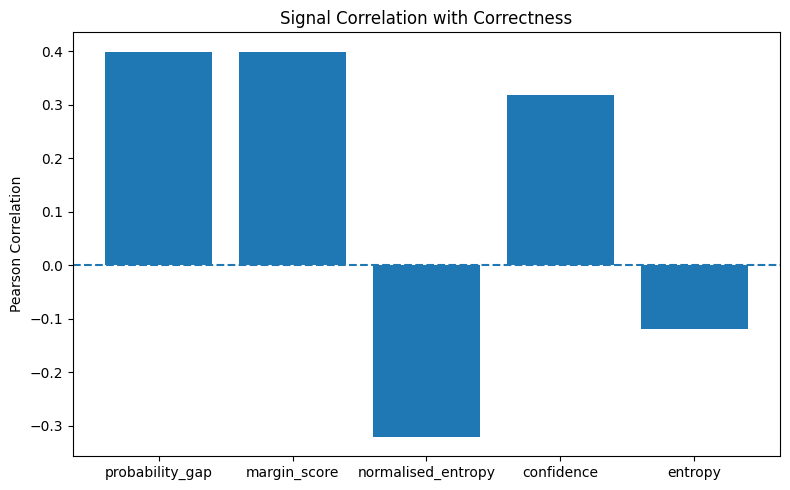

In [27]:
plt.figure(figsize=(8,5))

plt.bar(
    pearson_table["Signal"],
    pearson_table["Correlation"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.ylabel(
    "Pearson Correlation"
)

plt.title(
    "Signal Correlation with Correctness"
)

plt.tight_layout()

plt.savefig(
    "signal_correlation_comparison.png"
)

plt.show()

**STEP 3.5 — Signal Distributions by Correctness**

In [28]:
for signal in signals:

    summary = (

        analysis_df

        .groupby("correct")

        [signal]

        .agg([
            "mean",
            "std"
        ])

    )

    print("\n")
    print("=" * 60)
    print(signal.upper())
    print("=" * 60)

    print(summary)



CONFIDENCE
             mean       std
correct                    
0        0.307673  0.103745
1        0.387736  0.132860


ENTROPY
             mean       std
correct                    
0        1.514077  0.328170
1        1.428304  0.381395


NORMALISED_ENTROPY
             mean       std
correct                    
0        0.963469  0.036898
1        0.927261  0.065769


MARGIN_SCORE
             mean       std
correct                    
0        0.062801  0.074733
1        0.155167  0.129875


PROBABILITY_GAP
             mean       std
correct                    
0        0.062801  0.074733
1        0.155167  0.129875


**STEP 3.6 — Boxplot Comparison**

<Figure size 700x400 with 0 Axes>

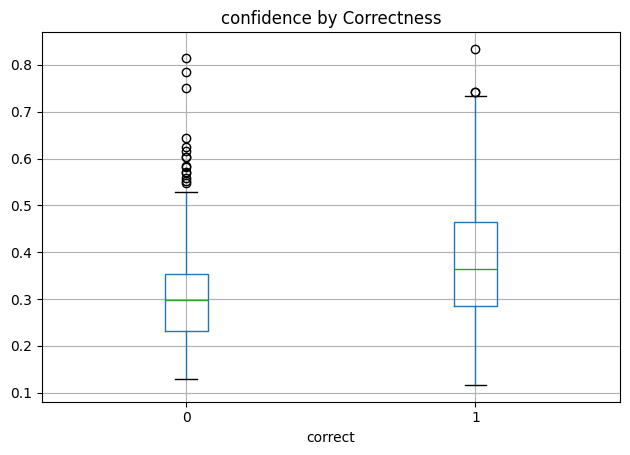

<Figure size 700x400 with 0 Axes>

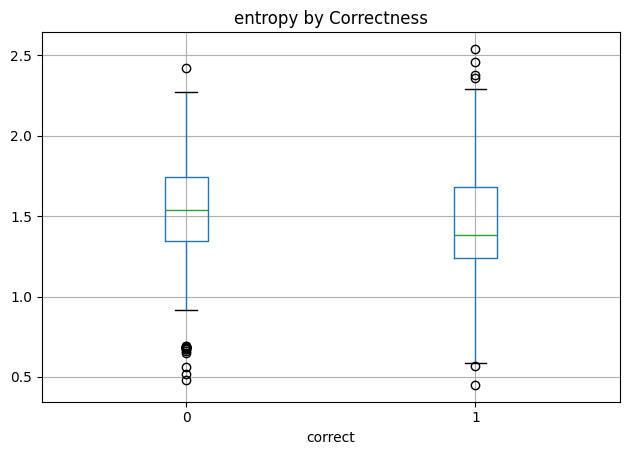

<Figure size 700x400 with 0 Axes>

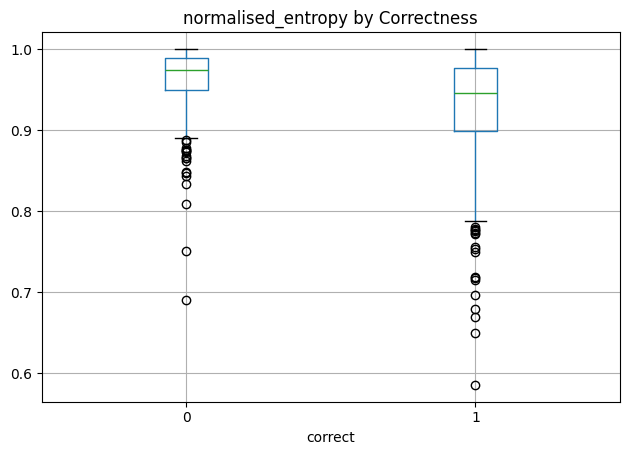

<Figure size 700x400 with 0 Axes>

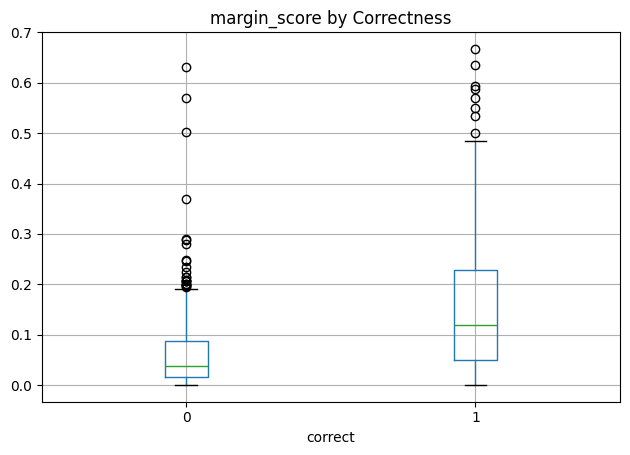

<Figure size 700x400 with 0 Axes>

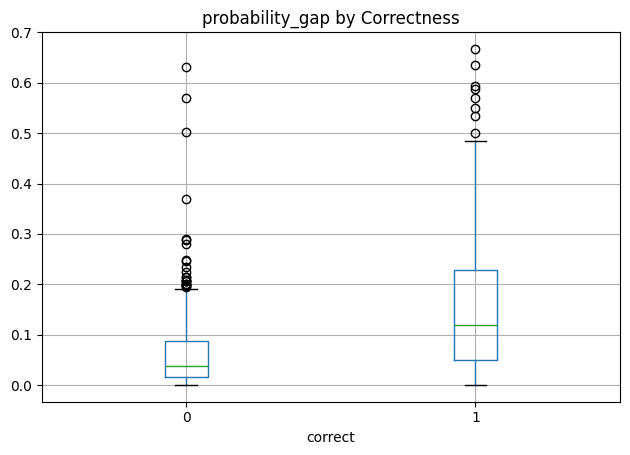

In [29]:
for signal in signals:

    plt.figure(figsize=(7,4))

    analysis_df.boxplot(
        column=signal,
        by="correct"
    )

    plt.title(
        f"{signal} by Correctness"
    )

    plt.suptitle("")

    plt.tight_layout()

    plt.savefig(
        f"{signal}_boxplot.png"
    )

    plt.show()

**STEP 3.7 — ROC-AUC Analysis**

In [30]:
from sklearn.metrics import roc_auc_score

auc_results = []

for signal in signals:

    values = analysis_df[signal]

    if "entropy" in signal:

        values = -values

    auc = roc_auc_score(
        analysis_df["correct"],
        values
    )

    auc_results.append({
        "Signal": signal,
        "ROC_AUC": auc
    })

auc_table = pd.DataFrame(
    auc_results
)

auc_table = auc_table.sort_values(
    "ROC_AUC",
    ascending=False
)

print(auc_table)

               Signal   ROC_AUC
4     probability_gap  0.752871
3        margin_score  0.752871
0          confidence  0.685464
2  normalised_entropy  0.685422
1             entropy  0.576799


**STEP 3.8 — ROC-AUC Comparison Visualisation**

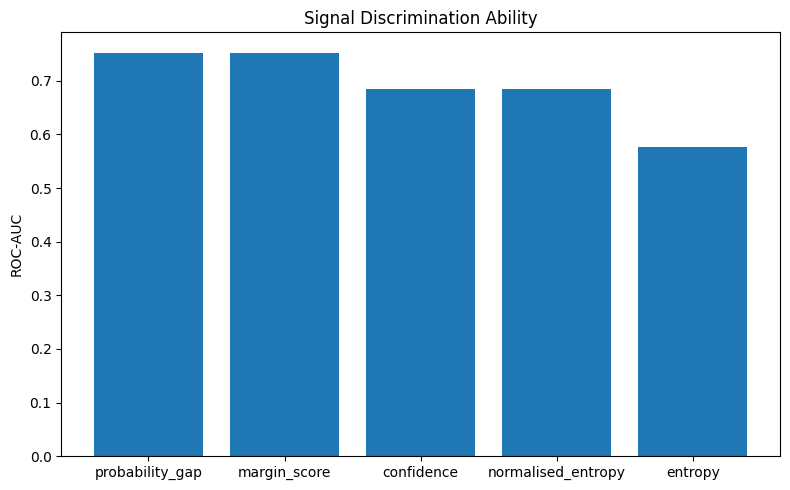

In [31]:
plt.figure(figsize=(8,5))

plt.bar(
    auc_table["Signal"],
    auc_table["ROC_AUC"]
)

plt.ylabel(
    "ROC-AUC"
)

plt.title(
    "Signal Discrimination Ability"
)

plt.tight_layout()

plt.savefig(
    "signal_auc_comparison.png"
)

plt.show()

Pearson correlation measures the strength of the linear association between each uncertainty signal and prediction correctness. To complement this analysis, the Mann–Whitney U test is used because correctness is binary and the signal distributions are not assumed to follow a normal distribution. Together, these analyses assess both association strength and statistical significance.

**STEP 3.8B — Signal Significance Testing**

In [32]:
from scipy.stats import mannwhitneyu

for signal in signals:

    correct_values = analysis_df[
        analysis_df["correct"] == 1
    ][signal]

    incorrect_values = analysis_df[
        analysis_df["correct"] == 0
    ][signal]

    stat, p = mannwhitneyu(
        correct_values,
        incorrect_values
    )

    print(
        signal,
        p
    )

confidence 4.493079648445755e-20
entropy 0.00014504161374049958
normalised_entropy 4.580472824327601e-20
margin_score 6.54453293906669e-36
probability_gap 6.54453293906669e-36


In [33]:
significance_results = []

for signal in signals:

    correct_values = analysis_df[
        analysis_df["correct"] == 1
    ][signal]

    incorrect_values = analysis_df[
        analysis_df["correct"] == 0
    ][signal]

    stat, p = mannwhitneyu(
        correct_values,
        incorrect_values,
        alternative="two-sided"
    )

    significance_results.append({

        "Signal": signal,

        "Statistic": stat,

        "P_Value": p

    })

significance_table = pd.DataFrame(
    significance_results
)

print(significance_table)

               Signal  Statistic       P_Value
0          confidence   114371.0  4.493080e-20
1             entropy    70612.0  1.450416e-04
2  normalised_entropy    52488.0  4.580473e-20
3        margin_score   125618.0  6.544533e-36
4     probability_gap   125618.0  6.544533e-36


In [34]:
significance_table.to_csv(
    "signal_significance.csv",
    index=False
)

**STEP 3.9 — Signal Ranking Table**

In [35]:
final_signal_ranking = (

    pearson_table

    [["Signal", "Correlation"]]

    .merge(
        auc_table,
        on="Signal"
    )

)

print(
    final_signal_ranking
)

               Signal  Correlation   ROC_AUC
0     probability_gap     0.399033  0.752871
1        margin_score     0.399033  0.752871
2  normalised_entropy    -0.320993  0.685422
3          confidence     0.318324  0.685464
4             entropy    -0.119717  0.576799


Margin Score and Probability Gap achieve identical Pearson correlation and ROC-AUC values because both quantify the difference between the highest and second-highest option probabilities. They are retained as separate signals because both names appear in the uncertainty estimation literature. Their identical rankings therefore reflect mathematical equivalence rather than independent empirical findings

**STEP 3.10 — Save Results**

In [36]:
final_signal_ranking.to_csv(

    "signal_correctness_ranking.csv",

    index=False

)

print(
    "Signal ranking saved."
)

Signal ranking saved.


**STEP 4 — Signal Calibration Analysis**

The previous step demonstrated that option-likelihood signals exhibit stronger relationships with prediction correctness than baseline confidence.

In particular, margin score and probability gap achieved higher correlation and ROC-AUC values than the original confidence estimate.

The objective of this step is to determine whether these signals also produce improved calibration behaviour.

Calibration measures whether reliability estimates correspond to empirical correctness.


**STEP 4.1 — Import Libraries**

In [37]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

**STEP 4.2 — Define ECE Function**

In [38]:
def compute_ece(
    confidences,
    correctness,
    n_bins=10
):

    bins = np.linspace(
        0,
        1,
        n_bins + 1
    )

    ece = 0

    for i in range(n_bins):

        mask = (
            (confidences > bins[i]) &
            (confidences <= bins[i+1])
        )

        if np.sum(mask) > 0:

            acc = np.mean(
                correctness[mask]
            )

            conf = np.mean(
                confidences[mask]
            )

            ece += (
                np.sum(mask)
                /
                len(confidences)
            ) * abs(acc - conf)

    return ece

**STEP 4.3 — Prepare Signals**

In [39]:
correctness = (
    analysis_df["correct"]
    .astype(int)
    .values
)

signal_dict = {

    "Confidence":
        analysis_df["confidence"],

    "Normalised Entropy":
        1 - analysis_df["normalised_entropy"],

    "Margin Score":
        analysis_df["margin_score"],

    "Probability Gap":
        analysis_df["probability_gap"]
}

Expected Calibration Error was computed using ten equally spaced confidence bins. Ten bins were selected because this configuration is widely adopted in the calibration literature and provides a practical balance between calibration resolution and statistical stability

**STEP 4.4 — Compute ECE for All Signals**

In [40]:
ece_results = []

for signal_name, signal_values in signal_dict.items():

    ece = compute_ece(
        signal_values.values,
        correctness
    )

    ece_results.append({

        "Signal":
            signal_name,

        "ECE":
            ece
    })

ece_table = pd.DataFrame(
    ece_results
)

ece_table = ece_table.sort_values(
    "ECE"
)

print(ece_table)

               Signal       ECE
0          Confidence  0.158951
2        Margin Score  0.396015
3     Probability Gap  0.396015
1  Normalised Entropy  0.450674


**STEP 4.5 — Calibration Ranking**

In [41]:
ece_table["Rank"] = range(
    1,
    len(ece_table)+1
)

print(ece_table)

               Signal       ECE  Rank
0          Confidence  0.158951     1
2        Margin Score  0.396015     2
3     Probability Gap  0.396015     3
1  Normalised Entropy  0.450674     4


**STEP 4.6 — Calibration Comparison Visualisation**

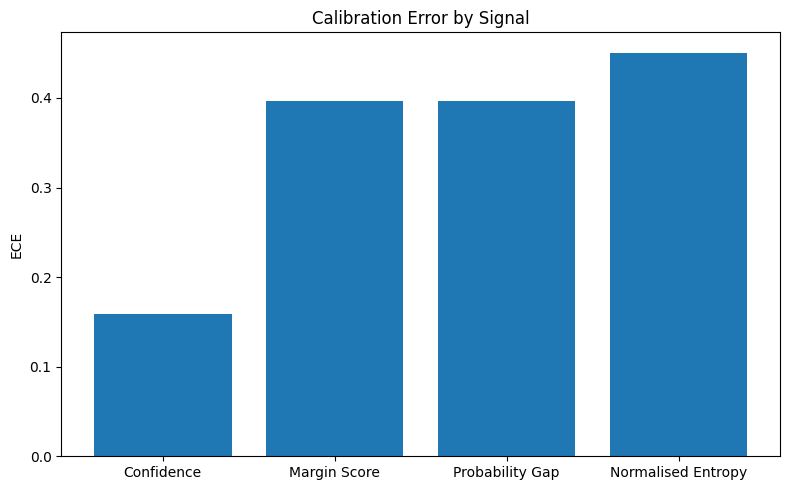

In [42]:
plt.figure(figsize=(8,5))

plt.bar(

    ece_table["Signal"],

    ece_table["ECE"]
)

plt.ylabel("ECE")

plt.title(
    "Calibration Error by Signal"
)

plt.tight_layout()

plt.savefig(
    "signal_ece_comparison.png"
)

plt.show()

**STEP 4.7 — Reliability Diagram Analysis**

In [43]:
def reliability_points(
    confidences,
    correctness,
    n_bins=10
):

    bins = np.linspace(
        0,
        1,
        n_bins + 1
    )

    mean_conf = []
    mean_acc = []

    for i in range(n_bins):

        mask = (
            (confidences > bins[i]) &
            (confidences <= bins[i+1])
        )

        if np.sum(mask) > 0:

            mean_conf.append(
                np.mean(
                    confidences[mask]
                )
            )

            mean_acc.append(
                np.mean(
                    correctness[mask]
                )
            )

    return mean_conf, mean_acc

The reliability diagrams demonstrate that different confidence signals exhibit different calibration behaviour. Signals whose empirical accuracy more closely follows the diagonal indicate better calibrated uncertainty estimates, whereas larger deviations indicate greater calibration error. These visual observations are consistent with the quantitative ECE results reported above.

**STEP 4.8 — Generate Reliability Curves**

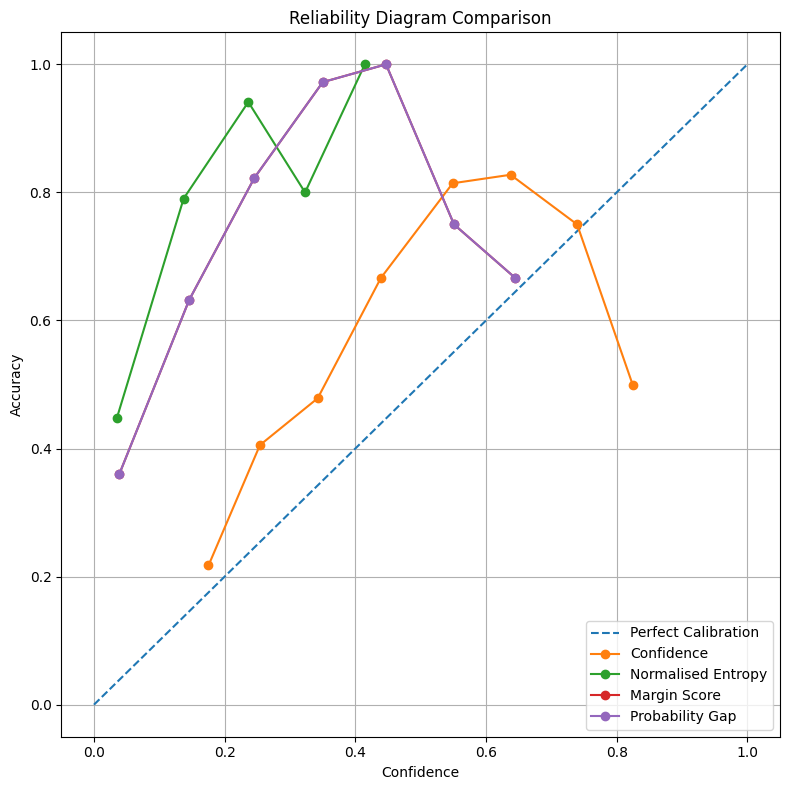

In [44]:
plt.figure(figsize=(8,8))

plt.plot(
    [0,1],
    [0,1],
    "--",
    label="Perfect Calibration"
)

for signal_name, signal_values in signal_dict.items():

    confs, accs = reliability_points(
        signal_values.values,
        correctness
    )

    plt.plot(
        confs,
        accs,
        marker="o",
        label=signal_name
    )

plt.xlabel(
    "Confidence"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Reliability Diagram Comparison"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "signal_reliability_comparison.png"
)

plt.show()

Bootstrap resampling was used to estimate confidence intervals because the sampling distribution of Expected Calibration Error is not analytically known. A total of 1,000 bootstrap resamples were generated to obtain stable interval estimates while maintaining reasonable computational efficiency.

**STEP 4.9 — Bootstrap ECE Confidence Intervals**

In [45]:
n_bootstrap = 1000

ece_bootstrap_results = []

for signal_name, signal_values in signal_dict.items():

    ece_samples = []

    for _ in range(n_bootstrap):

        indices = np.random.choice(
            len(signal_values),
            size=len(signal_values),
            replace=True
        )

        boot_signal = (
            signal_values.values[indices]
        )

        boot_correct = (
            correctness[indices]
        )

        ece = compute_ece(
            boot_signal,
            boot_correct
        )

        ece_samples.append(ece)

    ece_bootstrap_results.append({

        "Signal":
            signal_name,

        "Mean_ECE":
            np.mean(ece_samples),

        "CI_Lower":
            np.percentile(
                ece_samples,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                ece_samples,
                97.5
            )
    })

ece_ci_table = pd.DataFrame(
    ece_bootstrap_results
)

print(ece_ci_table)

               Signal  Mean_ECE  CI_Lower  CI_Upper
0          Confidence  0.161403  0.130580  0.192019
1  Normalised Entropy  0.450596  0.418194  0.482197
2        Margin Score  0.397587  0.366710  0.429580
3     Probability Gap  0.396122  0.364489  0.427817


**STEP 4.10 — Calibration Confidence Interval Visualisation**

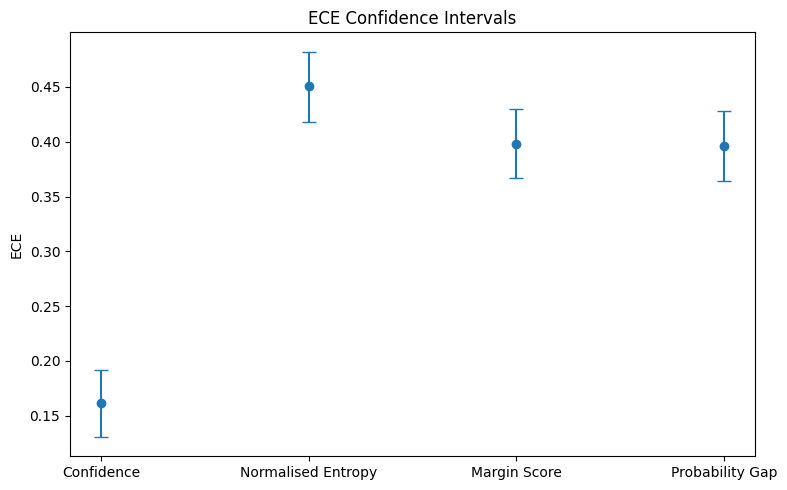

In [46]:
plt.figure(figsize=(8,5))

plt.errorbar(

    ece_ci_table["Signal"],

    ece_ci_table["Mean_ECE"],

    yerr=[
        ece_ci_table["Mean_ECE"]
        -
        ece_ci_table["CI_Lower"],

        ece_ci_table["CI_Upper"]
        -
        ece_ci_table["Mean_ECE"]
    ],

    fmt="o",
    capsize=5
)

plt.ylabel(
    "ECE"
)

plt.title(
    "ECE Confidence Intervals"
)

plt.tight_layout()

plt.savefig(
    "ece_confidence_intervals.png"
)

plt.show()

**STEP 4.11 — Final Calibration Ranking**

In [47]:
final_calibration_table = (

    ece_table

    .merge(
        ece_ci_table,
        on="Signal"
    )

)

final_calibration_table = (

    final_calibration_table

    .sort_values(
        "ECE"
    )

)

final_calibration_table["Rank"] = range(

    1,

    len(final_calibration_table)+1
)

print(
    final_calibration_table
)

               Signal       ECE  Rank  Mean_ECE  CI_Lower  CI_Upper
0          Confidence  0.158951     1  0.161403  0.130580  0.192019
1        Margin Score  0.396015     2  0.397587  0.366710  0.429580
2     Probability Gap  0.396015     3  0.396122  0.364489  0.427817
3  Normalised Entropy  0.450674     4  0.450596  0.418194  0.482197


In [48]:
signal_names = {

    "confidence": "Confidence",

    "margin_score": "Margin Score",

    "probability_gap": "Probability Gap",

    "normalised_entropy": "Normalised Entropy",

    "entropy": "Entropy"

}

final_signal_ranking["Signal"] = (
    final_signal_ranking["Signal"]
    .replace(signal_names)
)

final_signal_ranking = (
    final_signal_ranking[
        final_signal_ranking["Signal"] != "Entropy"
    ]
)

In [49]:
comparison_ranking = pearson_table[
    ["Signal", "Correlation"]
].merge(
    auc_table,
    on="Signal"
)

print(comparison_ranking)

               Signal  Correlation   ROC_AUC
0     probability_gap     0.399033  0.752871
1        margin_score     0.399033  0.752871
2  normalised_entropy    -0.320993  0.685422
3          confidence     0.318324  0.685464
4             entropy    -0.119717  0.576799


Overall, calibration analysis demonstrates that lower Expected Calibration Error does not necessarily imply stronger discrimination performance. Consequently, calibration and discrimination should be evaluated jointly when selecting confidence signals for reliable uncertainty estimation.

**STEP 4.11A — Standardise Signal Names**

In [50]:
comparison_ranking["Signal"] = comparison_ranking["Signal"].replace({

    "confidence": "Confidence",

    "margin_score": "Margin Score",

    "probability_gap": "Probability Gap",

    "normalised_entropy": "Normalised Entropy"

})



To ensure consistent comparison across calibration and discrimination analyses,
signal names are standardised before merging result tables.
This prevents formatting differences from causing missing entries in the final comparison.

**STEP 4.11B — Calibration vs Discrimination Analysis**

Before combining the calibration and discrimination results, the
discrimination ranking is inspected to verify that all confidence
signals are present. This diagnostic step helps identify any
accidental omissions introduced during earlier processing.

In [51]:
print("=" * 60)
print("DISCRIMINATION RANKING")
print("=" * 60)

print(final_signal_ranking)

print("\nSignals present:")

print(
    final_signal_ranking["Signal"].tolist()
)

DISCRIMINATION RANKING
               Signal  Correlation   ROC_AUC
0     Probability Gap     0.399033  0.752871
1        Margin Score     0.399033  0.752871
2  Normalised Entropy    -0.320993  0.685422
3          Confidence     0.318324  0.685464

Signals present:
['Probability Gap', 'Margin Score', 'Normalised Entropy', 'Confidence']


In [52]:
final_signal_ranking = (

    final_signal_ranking

    .drop_duplicates(
        subset="Signal"
    )

)

In [53]:
print("=" * 60)
print("AFTER drop_duplicates")
print("=" * 60)

print(final_signal_ranking)

print("\nSignals:")

print(final_signal_ranking["Signal"].tolist())

AFTER drop_duplicates
               Signal  Correlation   ROC_AUC
0     Probability Gap     0.399033  0.752871
1        Margin Score     0.399033  0.752871
2  Normalised Entropy    -0.320993  0.685422
3          Confidence     0.318324  0.685464

Signals:
['Probability Gap', 'Margin Score', 'Normalised Entropy', 'Confidence']


In [54]:
calibration_discrimination_table = pd.merge(

    final_signal_ranking[
        ["Signal", "ROC_AUC"]
    ],

    final_calibration_table[
        ["Signal", "ECE"]
    ],

    on="Signal",

    how="inner"

)

calibration_discrimination_table = (

    calibration_discrimination_table

    .sort_values(
        "ROC_AUC",
        ascending=False
    )

    .reset_index(drop=True)

)

print("=" * 60)
print("CALIBRATION VS DISCRIMINATION")
print("=" * 60)

print(calibration_discrimination_table)

CALIBRATION VS DISCRIMINATION
               Signal   ROC_AUC       ECE
0     Probability Gap  0.752871  0.396015
1        Margin Score  0.752871  0.396015
2          Confidence  0.685464  0.158951
3  Normalised Entropy  0.685422  0.450674


1. Calibration and discrimination evaluate complementary aspects of
confidence estimation.

2. Confidence achieves the lowest Expected Calibration Error, indicating that its probability estimates are the most closely
aligned with observed empirical accuracy.

3. Margin Score and Probability Gap achieve substantially higher ROC-AUC values,demonstrating stronger discrimination between
correct and incorrect predictions despite exhibiting larger calibration errors.

These findings indicate that calibration and discrimination capture different properties of uncertainty estimation and should therefore
be evaluated jointly when comparing confidence signals.

In [55]:
print(final_signal_ranking)

               Signal  Correlation   ROC_AUC
0     Probability Gap     0.399033  0.752871
1        Margin Score     0.399033  0.752871
2  Normalised Entropy    -0.320993  0.685422
3          Confidence     0.318324  0.685464


**STEP 4.11C — Verify Merge Integrity**

In [56]:
expected_signals = {

    "Confidence",

    "Margin Score",

    "Probability Gap",

    "Normalised Entropy"

}

actual_signals = set(

    calibration_discrimination_table["Signal"]

)

print(

    "Expected:",

    expected_signals

)

print(

    "Actual:",

    actual_signals

)

print(

    "Missing:",

    expected_signals - actual_signals

)

print(

    "Extra:",

    actual_signals - expected_signals

)

print(

    "All signals present:",

    expected_signals == actual_signals

)

Expected: {'Probability Gap', 'Margin Score', 'Confidence', 'Normalised Entropy'}
Actual: {'Margin Score', 'Confidence', 'Probability Gap', 'Normalised Entropy'}
Missing: set()
Extra: set()
All signals present: True


**STEP 4.12 — Save Calibration Results**

In [57]:
final_calibration_table.to_csv(

    "signal_calibration_ranking.csv",

    index=False

)

print(
    "Calibration results saved."
)

Calibration results saved.


**STEP 5 — Signal-Based Selective Prediction**

**STEP 5.1 — Select Candidate Signals**

In [58]:
signal_selection = {

    "Confidence":
        analysis_df["confidence"],

    "Margin Score":
        analysis_df["margin_score"],

    "Probability Gap":
        analysis_df["probability_gap"],

    "Normalised Entropy":
        1 - analysis_df["normalised_entropy"]
}

print(
    signal_selection.keys()
)

dict_keys(['Confidence', 'Margin Score', 'Probability Gap', 'Normalised Entropy'])


**STEP 5.2 — Define Threshold Grid**

In [59]:
thresholds = np.arange(
    0.0,
    1.01,
    0.05
)

print(
    thresholds
)

[0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65
 0.7  0.75 0.8  0.85 0.9  0.95 1.  ]


**STEP 5.3 — Compute Coverage and Accuracy**

In [60]:
all_results = []

for signal_name, signal_values in signal_selection.items():

    for threshold in thresholds:

        selected = (
            signal_values >= threshold
        )

        coverage = np.mean(
            selected
        )

        if np.sum(selected) > 0:

            accuracy = np.mean(
                correctness[selected]
            )

        else:

            accuracy = np.nan

        all_results.append({

            "Signal":
                signal_name,

            "Threshold":
                threshold,

            "Coverage":
                coverage,

            "Accuracy":
                accuracy
        })

selective_df = pd.DataFrame(
    all_results
)

print(
    selective_df.head()
)

       Signal  Threshold  Coverage  Accuracy
0  Confidence       0.00  1.000000  0.505508
1  Confidence       0.05  1.000000  0.505508
2  Confidence       0.10  1.000000  0.505508
3  Confidence       0.15  0.990208  0.505562
4  Confidence       0.20  0.915545  0.532086


**STEP 5.4 — Coverage–Accuracy Curves**

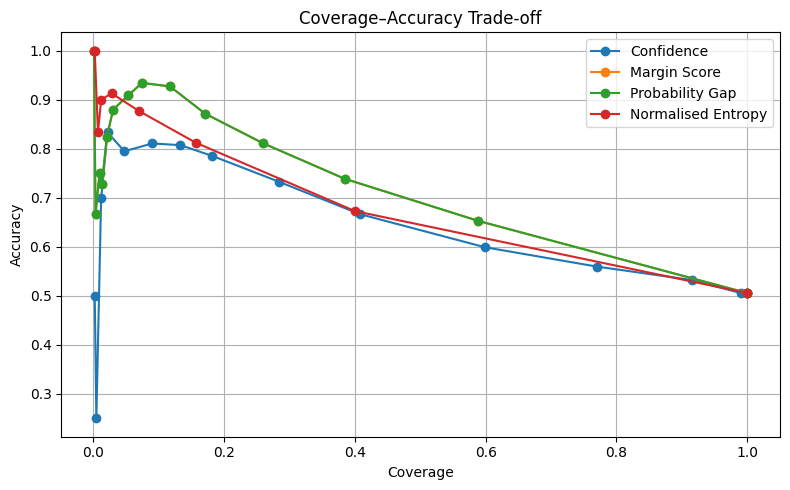

In [61]:
plt.figure(figsize=(8,5))

for signal_name in selective_df[
    "Signal"
].unique():

    subset = selective_df[
        selective_df["Signal"]
        == signal_name
    ]

    plt.plot(

        subset["Coverage"],

        subset["Accuracy"],

        marker="o",

        label=signal_name
    )

plt.xlabel(
    "Coverage"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Coverage–Accuracy Trade-off"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "signal_selective_prediction.png"
)

plt.show()

**STEP 5.5 — Best Accuracy at Practical Coverage**

In [62]:
practical_results = (

    selective_df[
        selective_df["Coverage"] >= 0.20
    ]
)

best_results = (

    practical_results

    .sort_values(
        "Accuracy",
        ascending=False
    )

    .groupby("Signal")

    .first()

    .reset_index()
)

print(
    best_results
)

               Signal  Threshold  Coverage  Accuracy
0          Confidence       0.40  0.283966  0.732759
1        Margin Score       0.15  0.259486  0.811321
2  Normalised Entropy       0.05  0.400245  0.672783
3     Probability Gap       0.15  0.259486  0.811321


**STEP 5.6 — Risk–Coverage Curve Analysis**

In [63]:
selective_df["Risk"] = (
    1 - selective_df["Accuracy"]
)

print(
    selective_df.head()
)

       Signal  Threshold  Coverage  Accuracy      Risk
0  Confidence       0.00  1.000000  0.505508  0.494492
1  Confidence       0.05  1.000000  0.505508  0.494492
2  Confidence       0.10  1.000000  0.505508  0.494492
3  Confidence       0.15  0.990208  0.505562  0.494438
4  Confidence       0.20  0.915545  0.532086  0.467914


**STEP 5.7 — Risk–Coverage Visualisation**

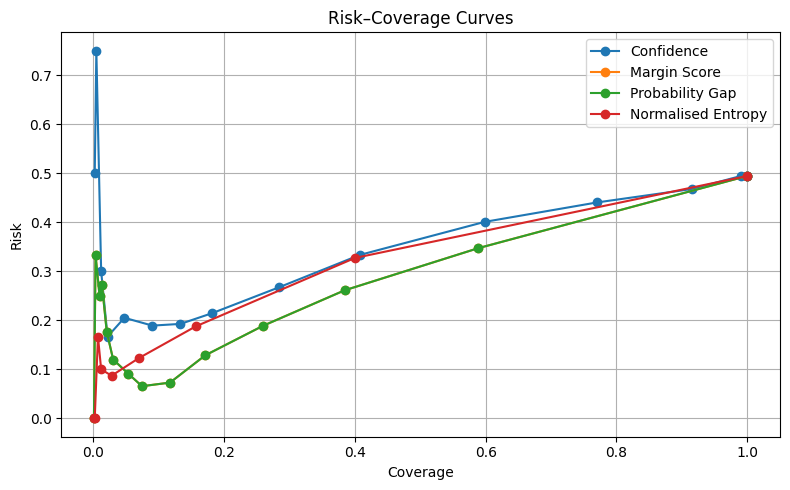

In [64]:
plt.figure(figsize=(8,5))

for signal_name in selective_df[
    "Signal"
].unique():

    subset = selective_df[
        selective_df["Signal"]
        == signal_name
    ]

    plt.plot(

        subset["Coverage"],

        subset["Risk"],

        marker="o",

        label=signal_name
    )

plt.xlabel(
    "Coverage"
)

plt.ylabel(
    "Risk"
)

plt.title(
    "Risk–Coverage Curves"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "risk_coverage_curves.png"
)

plt.show()

**STEP 5.8 — Area Under Risk–Coverage Curve (AURC)**

In [65]:
aurc_results = []

for signal_name in selective_df[
    "Signal"
].unique():

    subset = (

        selective_df[
            selective_df["Signal"]
            == signal_name
        ]

        .dropna()

        .sort_values(
            "Coverage"
        )
    )

    aurc = np.trapezoid(

        subset["Risk"],

        subset["Coverage"]
    )

    aurc_results.append({

        "Signal":
            signal_name,

        "AURC":
            aurc
    })

aurc_table = pd.DataFrame(
    aurc_results
)

aurc_table = aurc_table.sort_values(
    "AURC"
)

print(
    aurc_table
)

               Signal      AURC
1        Margin Score  0.296035
2     Probability Gap  0.296035
3  Normalised Entropy  0.329494
0          Confidence  0.349734


**STEP 5.9 — AURC Comparison Visualisation**

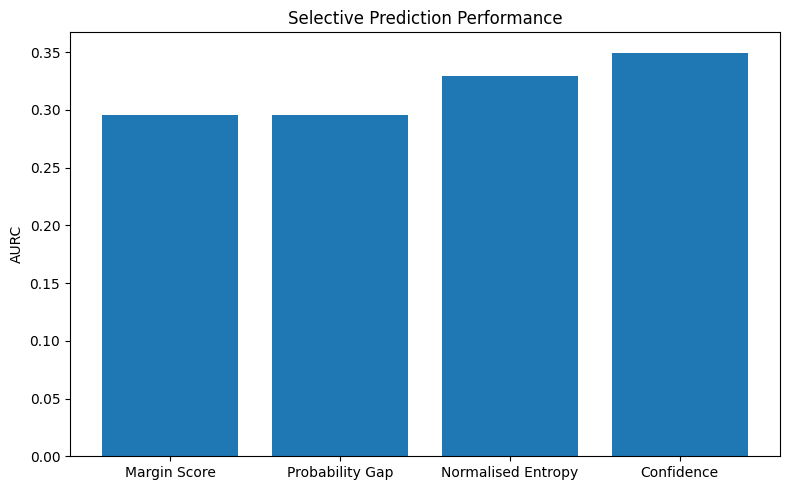

In [66]:
plt.figure(figsize=(8,5))

plt.bar(

    aurc_table["Signal"],

    aurc_table["AURC"]
)

plt.ylabel(
    "AURC"
)

plt.title(
    "Selective Prediction Performance"
)

plt.tight_layout()

plt.savefig(
    "aurc_comparison.png"
)

plt.show()

**STEP 5.10 — Bootstrap Confidence Intervals for AURC**

In [67]:
n_bootstrap = 1000

aurc_bootstrap_results = []


bootstrap_distributions = {}

for signal_name in signal_selection:

    signal_values = signal_selection[
        signal_name
    ].values

    aurc_samples = []

    for _ in range(n_bootstrap):

        indices = np.random.choice(
            len(signal_values),
            len(signal_values),
            replace=True
        )

        boot_signal = signal_values[
            indices
        ]

        boot_correct = correctness[
            indices
        ]

        rows = []

        for threshold in thresholds:

            selected = (
                boot_signal >= threshold
            )

            coverage = np.mean(
                selected
            )

            if np.sum(selected) > 0:

                accuracy = np.mean(
                    boot_correct[selected]
                )

            else:

                accuracy = np.nan

            rows.append({

                "Coverage":
                    coverage,

                "Risk":
                    1 - accuracy
            })

        temp = pd.DataFrame(
            rows
        )

        temp = (

            temp

            .dropna()

            .sort_values(
                "Coverage"
            )
        )

        aurc = np.trapezoid(

            temp["Risk"],

            temp["Coverage"]
        )

        aurc_samples.append(
            aurc
        )

    aurc_bootstrap_results.append({

        "Signal":
            signal_name,

        "Mean_AURC":
            np.mean(
                aurc_samples
            ),

        "CI_Lower":
            np.percentile(
                aurc_samples,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                aurc_samples,
                97.5
            )

    })
    bootstrap_distributions[signal_name] = aurc_samples

aurc_ci_table = pd.DataFrame(
    aurc_bootstrap_results
)

print(
    aurc_ci_table
)

               Signal  Mean_AURC  CI_Lower  CI_Upper
0          Confidence   0.348921  0.305884  0.390996
1        Margin Score   0.294571  0.257327  0.334255
2     Probability Gap   0.295260  0.254125  0.334656
3  Normalised Entropy   0.328904  0.287745  0.370907


**STEP 5.11 — Statistical Significance Testing**

In [68]:
paired_results = []

comparisons = [
    ("Margin Score", "Confidence"),
    ("Probability Gap", "Confidence"),
    ("Normalised Entropy", "Confidence")
]

for better, baseline in comparisons:

    difference = (
        np.array(bootstrap_distributions[baseline])
        - np.array(bootstrap_distributions[better])
    )

    paired_results.append({

        "Comparison": f"{better} vs {baseline}",

        "Mean Difference":
            np.mean(difference),

        "CI Lower":
            np.percentile(difference,2.5),

        "CI Upper":
            np.percentile(difference,97.5)

    })

paired_table = pd.DataFrame(
    paired_results
)

print(paired_table)

                         Comparison  Mean Difference  CI Lower  CI Upper
0        Margin Score vs Confidence         0.054350 -0.002000  0.111932
1     Probability Gap vs Confidence         0.053661 -0.006684  0.110732
2  Normalised Entropy vs Confidence         0.020017 -0.037126  0.081134


In [69]:
paired_table["Significant"] = np.where(

    (paired_table["CI Lower"] > 0) |
    (paired_table["CI Upper"] < 0),

    "Yes",

    "No"

)

print(paired_table)

                         Comparison  Mean Difference  CI Lower  CI Upper  \
0        Margin Score vs Confidence         0.054350 -0.002000  0.111932   
1     Probability Gap vs Confidence         0.053661 -0.006684  0.110732   
2  Normalised Entropy vs Confidence         0.020017 -0.037126  0.081134   

  Significant  
0          No  
1          No  
2          No  


**STEP 5.11A — Mann–Whitney U Test on Bootstrap AURC**

In [70]:
from scipy.stats import mannwhitneyu

comparisons = [

    ("Margin Score", "Confidence"),

    ("Probability Gap", "Confidence"),

    ("Normalised Entropy", "Confidence")

]

results = []

for better, baseline in comparisons:

    statistic, p_value = mannwhitneyu(

        bootstrap_distributions[better],

        bootstrap_distributions[baseline],

        alternative="two-sided"

    )

    results.append({

        "Comparison": f"{better} vs {baseline}",

        "Statistic": statistic,

        "P-value": p_value

    })

significance_table = pd.DataFrame(results)

print(significance_table)

                         Comparison  Statistic        P-value
0        Margin Score vs Confidence    35197.0  1.021695e-283
1     Probability Gap vs Confidence    38884.0  2.873512e-279
2  Normalised Entropy vs Confidence   253399.0   2.683463e-81


Although the Mann–Whitney U tests indicate statistically significant differences between bootstrap AURC distributions, the paired bootstrap confidence intervals remain the primary evidence because they account for the paired evaluation design using identical bootstrap samples.

In [71]:
significance_table.to_csv(

    "aurc_significance_tests.csv",

    index=False

)

**STEP 5.12 — Final Selective Prediction Ranking**

In [72]:
final_selective_table = (

    aurc_table

    .merge(
        aurc_ci_table,
        on="Signal"
    )
)

final_selective_table = (

    final_selective_table

    .sort_values(
        "AURC"
    )
)

final_selective_table["Rank"] = range(

    1,

    len(final_selective_table)+1
)

print(
    final_selective_table
)

               Signal      AURC  Mean_AURC  CI_Lower  CI_Upper  Rank
0        Margin Score  0.296035   0.294571  0.257327  0.334255     1
1     Probability Gap  0.296035   0.295260  0.254125  0.334656     2
2  Normalised Entropy  0.329494   0.328904  0.287745  0.370907     3
3          Confidence  0.349734   0.348921  0.305884  0.390996     4


Margin Score and Probability Gap achieved the lowest AURC values, indicating superior selective prediction performance. However, because the paired bootstrap confidence intervals overlap zero, these improvements should be interpreted as consistent trends rather than definitive evidence of superiority over baseline confidence.

**STEP 5.13 — Save Results**

In [73]:
final_selective_table.to_csv(

    "signal_selective_prediction_ranking.csv",

    index=False
)

print(
    "Selective prediction results saved."
)

Selective prediction results saved.
